# **Import Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

# **Load the Dataset**

In [ ]:
df = pd.read_csv("/content/insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# **Dataset Structure and Data Types**

In [ ]:
df.shape

(1337, 7)

In [ ]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


# **Check for Missing Values**

In [ ]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


# **Check for Duplicate Values**

In [ ]:
df.duplicated().sum()

np.int64(1)

In [ ]:
df.drop_duplicates(inplace=True)

# **Part 2: Data Analysis & Insights**

### **Categorical Variables Distribution**

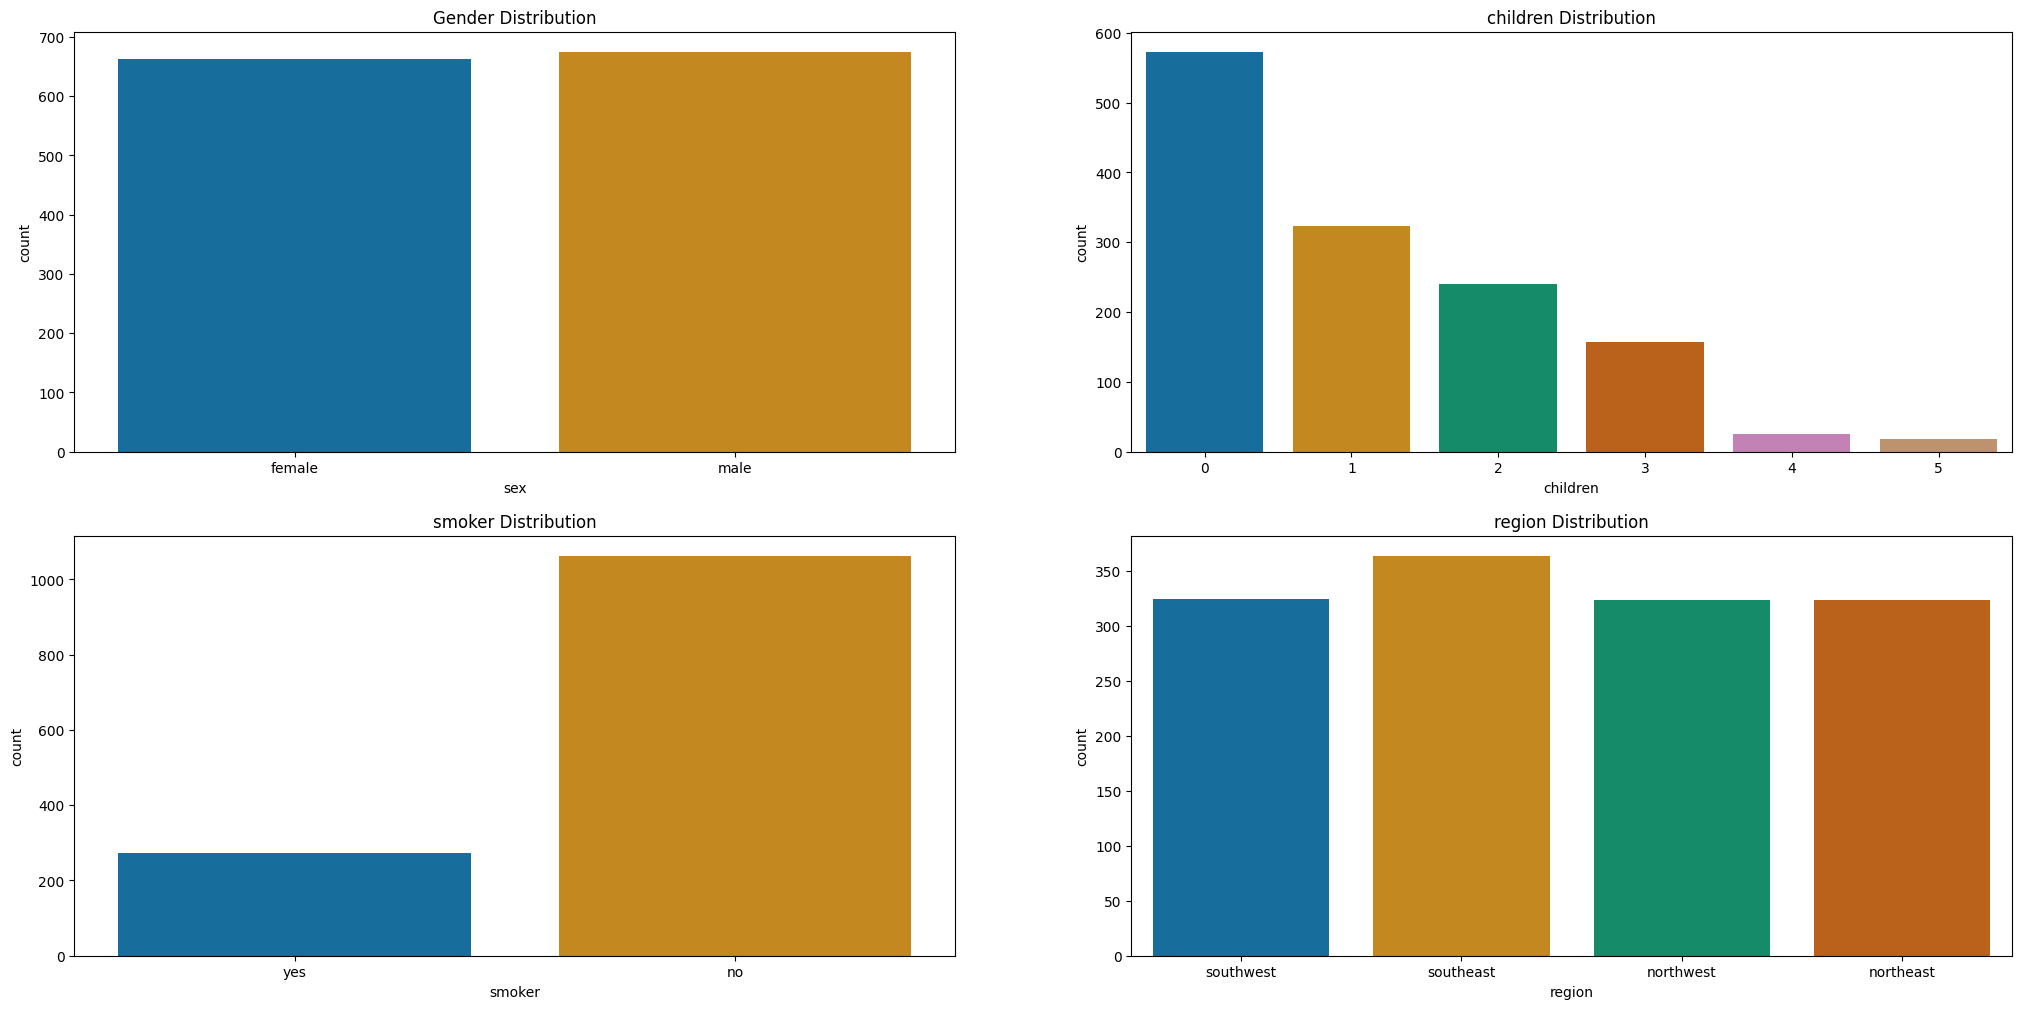

In [ ]:
plt.figure(figsize=(25,12))
plt.subplot(2,2,1)
sb.countplot(data = df, x = "sex" , palette = "colorblind")
plt.title("Gender Distribution")

plt.subplot(2,2,2)
sb.countplot(data = df, x = "children" , palette = "colorblind")
plt.title("children Distribution")

plt.subplot(2,2,3)
sb.countplot(data = df, x = "smoker" , palette = "colorblind")
plt.title("smoker Distribution")

plt.subplot(2,2,4)
sb.countplot(data = df, x = "region" , palette = "colorblind")
plt.title("region Distribution")

plt.show()


### **Numerical Variables Distribution**

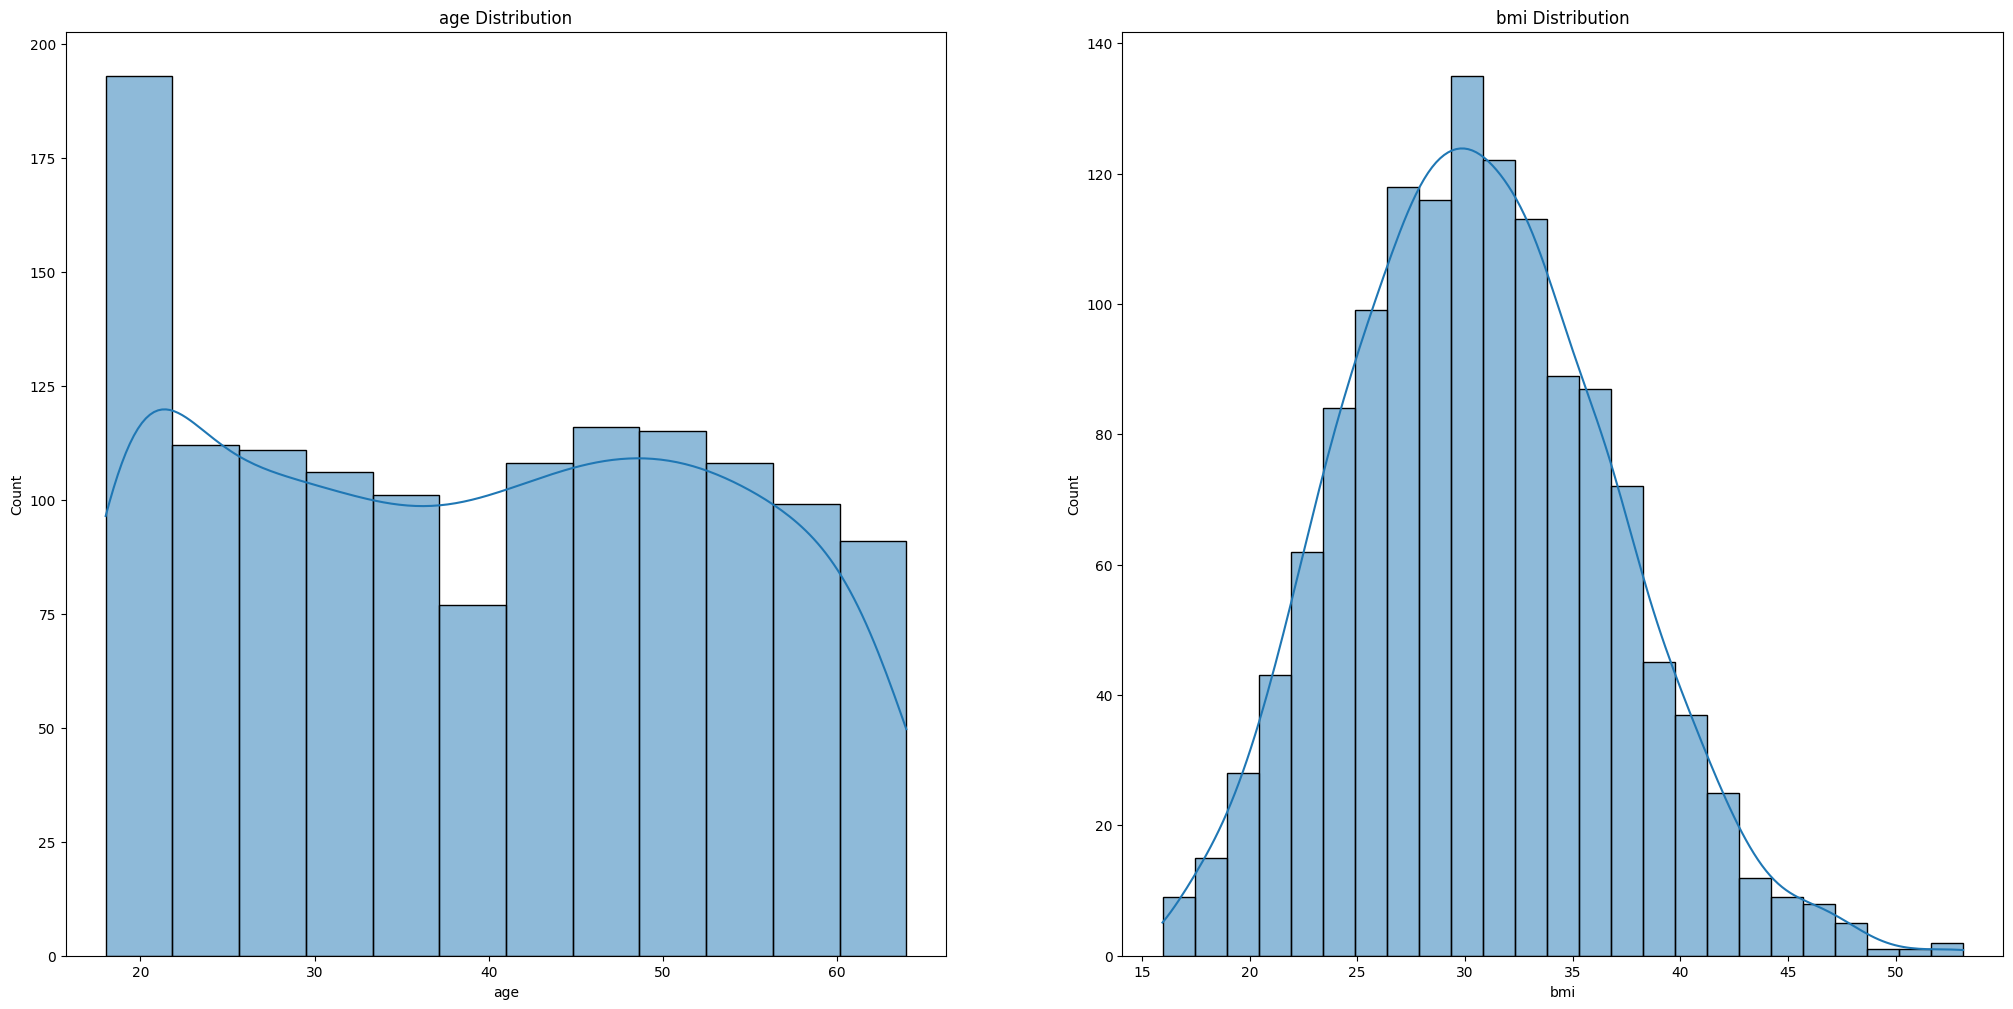

In [ ]:
plt.figure(figsize=(25,12))
plt.subplot(1,2,1)
sb.histplot(data = df, x = "age" , kde = True )
plt.title("age Distribution")

plt.subplot(1,2,2)
sb.histplot(data = df, x = "bmi" , kde = True )
plt.title("bmi Distribution")

plt.show()

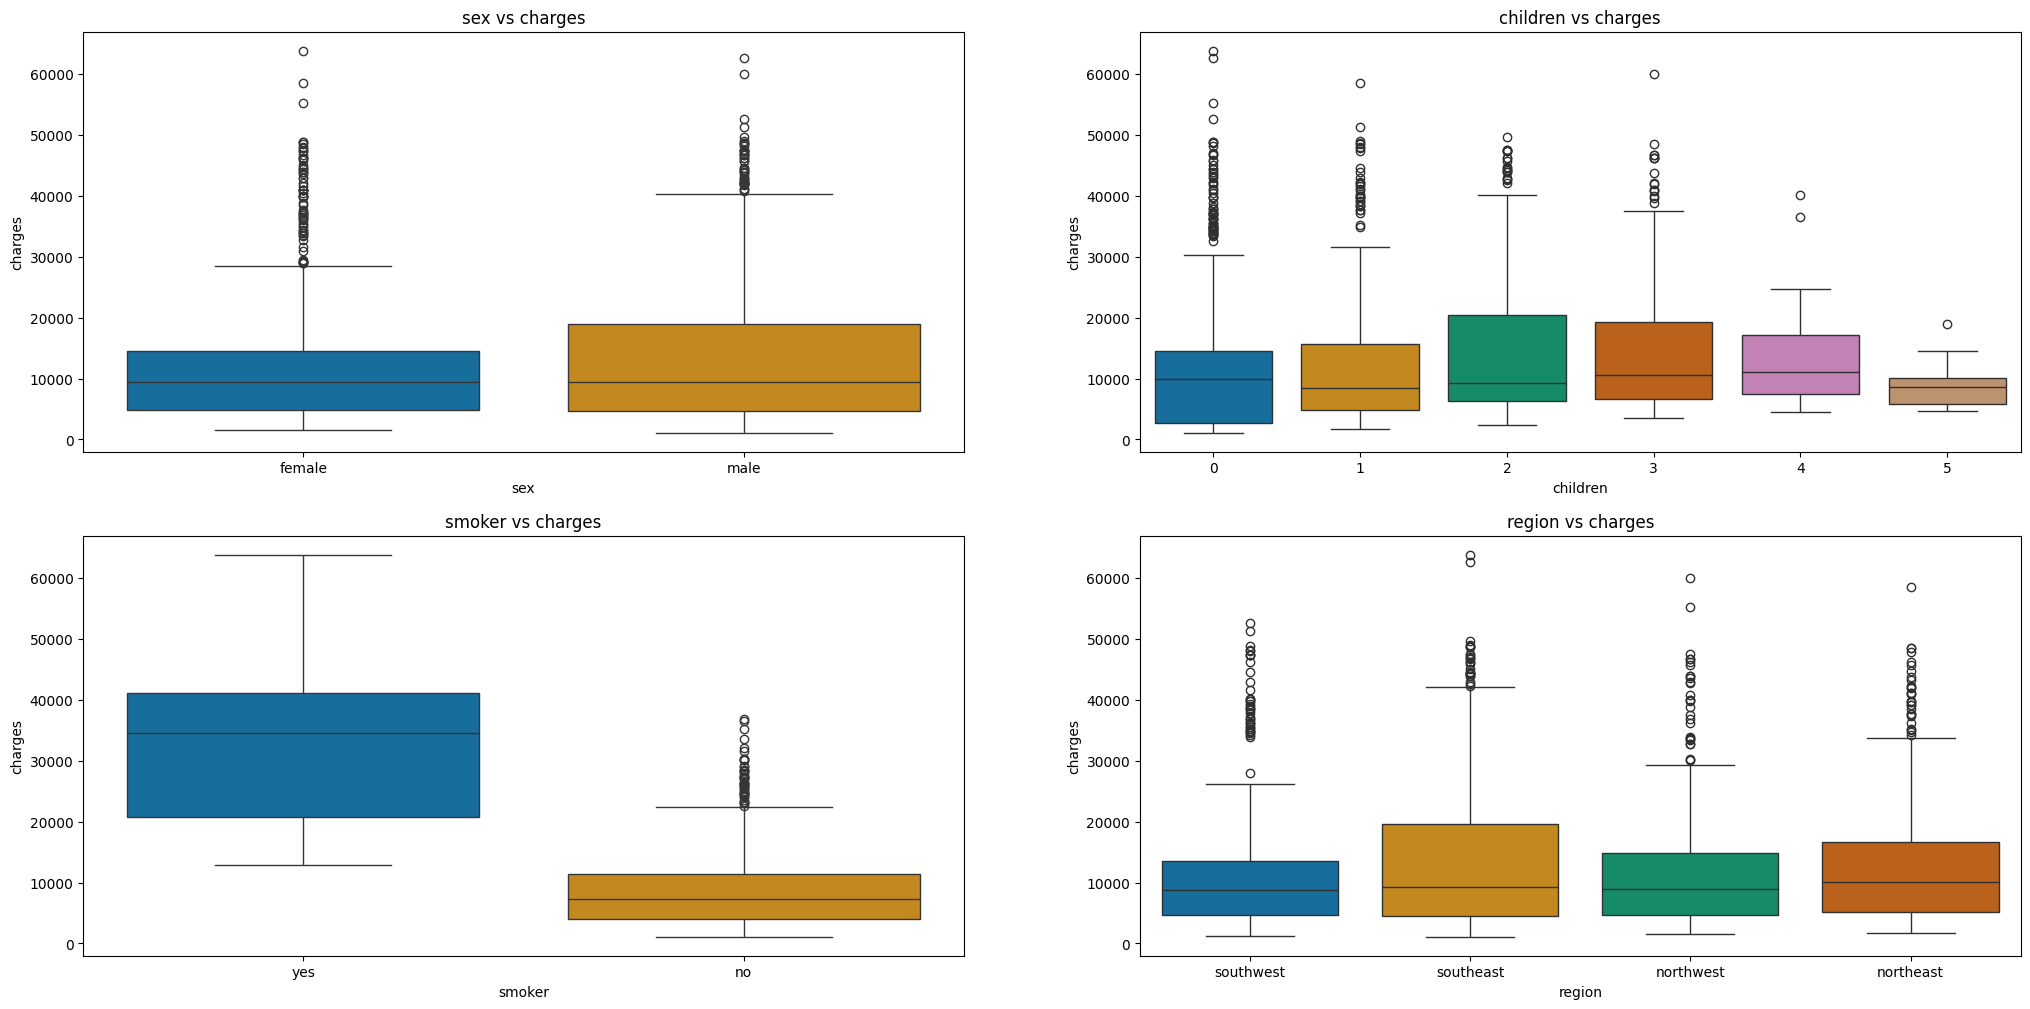

In [ ]:
plt.figure(figsize=(25,12))
plt.subplot(2,2,1)
sb.boxplot(data = df, x = "sex" , y = "charges" , palette = "colorblind")
plt.title("sex vs charges")

plt.subplot(2,2,2)
sb.boxplot(data = df, x = "children" , y = "charges" , palette = "colorblind")
plt.title("children vs charges")

plt.subplot(2,2,3)
sb.boxplot(data = df, x = "smoker" , y = "charges" , palette = "colorblind")
plt.title("smoker vs charges")

plt.subplot(2,2,4)
sb.boxplot(data = df, x = "region" , y = "charges" , palette = "colorblind")
plt.title("region vs charges")

plt.show()

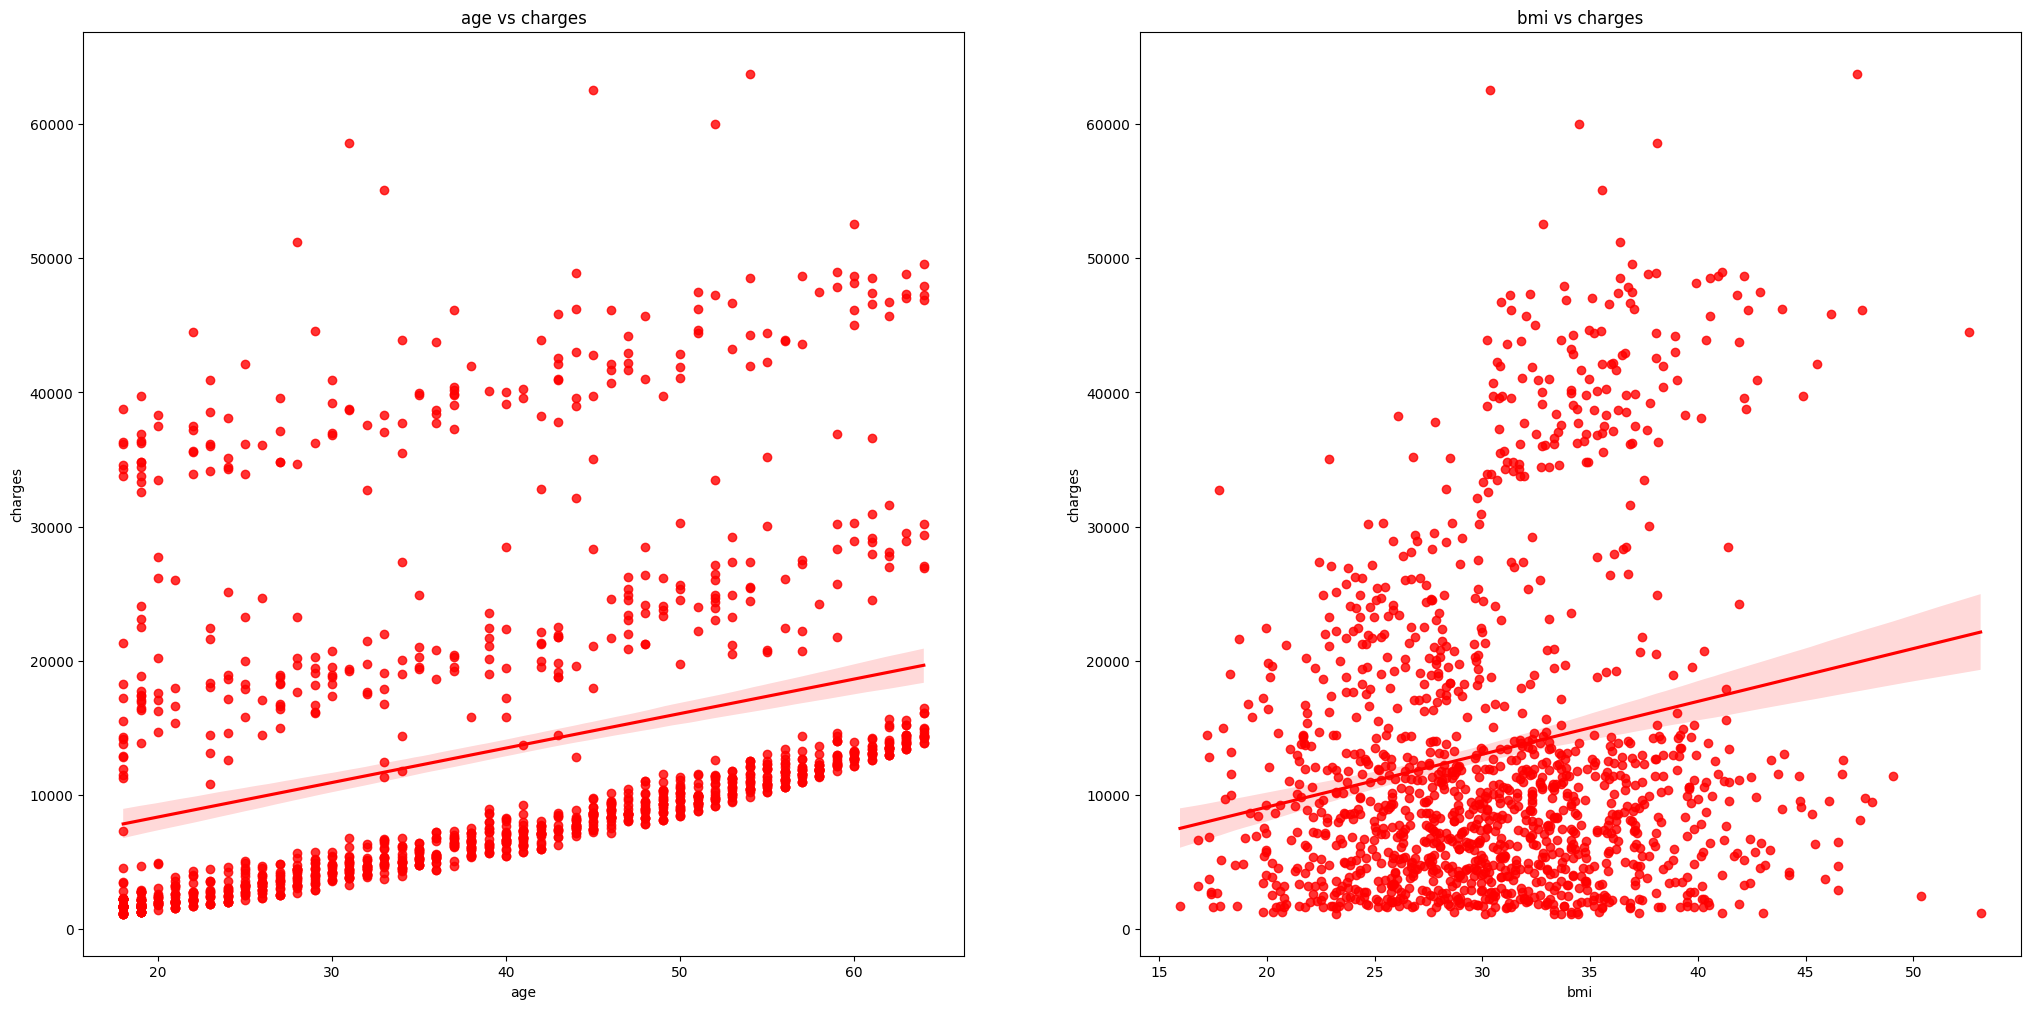

In [ ]:
plt.figure(figsize=(25,12))
plt.subplot(1,2,1)
sb.regplot(data = df, x = "age" , y = "charges" ,fit_reg=True , color = "red")
plt.title("age vs charges")

plt.subplot(1,2,2)
sb.regplot(data = df, x = "bmi" , y = "charges" ,fit_reg=True , color = "red")
plt.title("bmi vs charges")

plt.show()

### **Correlation Analysis**

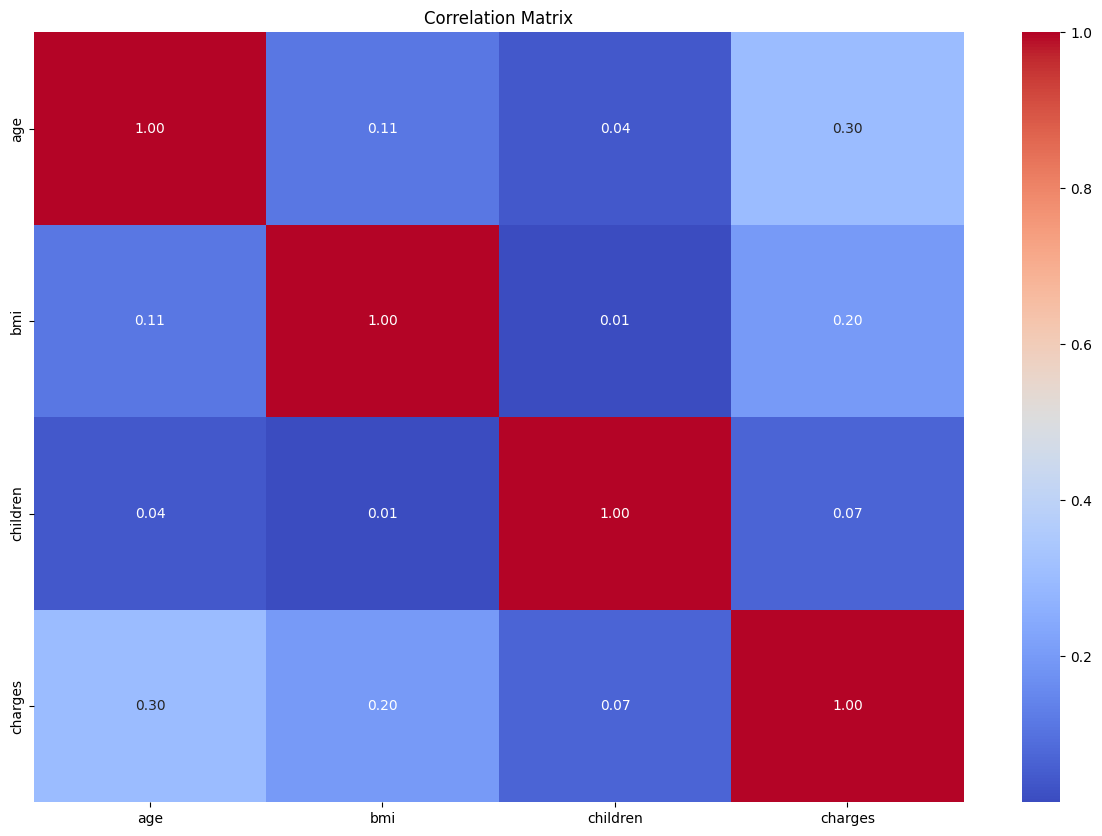

In [ ]:
plt.figure(figsize=(15,10))
correlation = df.corr(numeric_only= True)
sb.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

## Key Insights:

1. Insurance charges tend to increase with age.

2. BMI has a positive relationship with insurance charges,but the relationship is not very strong.

3. Smokers generally have substantially higher insurance
   charges than non-smokers.

4. Insurance charges vary across different regions,
   although the differences are relatively limited.

5. Gender does not appear to create a large difference
   in insurance charges.

6. The number of children does not show a strong linear
   relationship with insurance charges.

7. Smoking status appears to be one of the most important
   factors associated with insurance charges.

# **Part 3: Data Preprocessing**

# **Separate Features and Target**

In [ ]:
X = df.iloc[:,:-1]
y = df.iloc[:,-1]

In [ ]:
X

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest
...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest
1334,18,female,31.920,0,no,northeast
1335,18,female,36.850,0,no,southeast
1336,21,female,25.800,0,no,southwest


In [ ]:
y

,charges
0,16884.92400
1,1725.55230
2,4449.46200
3,21984.47061
4,3866.85520
...,...
1333,10600.54830
1334,2205.98080
1335,1629.83350
1336,2007.94500


In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

# **Encode Categorical Variables**

In [ ]:
categorical_cols = ['sex', 'smoker', 'region']

encoder = OneHotEncoder(drop = 'first',sparse_output= False)

X_train_encoded = encoder.fit_transform(X_train[categorical_cols])
X_test_encoded = encoder.transform(X_test[categorical_cols])

numerical_cols = ['age', 'bmi', 'children']

X_train_final = pd.concat([
    X_train[numerical_cols].reset_index(drop=True),
    pd.DataFrame(X_train_encoded, columns=encoder.get_feature_names_out(categorical_cols))
                          ],axis = 1)

In [ ]:
X_test_final = pd.concat([
    X_test[numerical_cols].reset_index(drop=True),
    pd.DataFrame(X_test_encoded, columns=encoder.get_feature_names_out(categorical_cols))
                          ],axis = 1)

In [ ]:
X_train_final

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,23,24.510,0,1.0,0.0,0.0,0.0,0.0
1,21,25.745,2,1.0,0.0,0.0,0.0,0.0
2,52,37.525,2,0.0,0.0,1.0,0.0,0.0
3,63,41.470,0,1.0,0.0,0.0,1.0,0.0
4,47,26.600,2,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
1064,51,34.960,2,0.0,1.0,0.0,0.0,0.0
1065,27,45.900,2,1.0,0.0,0.0,0.0,1.0
1066,20,22.000,1,1.0,0.0,0.0,0.0,1.0
1067,38,28.000,3,0.0,0.0,0.0,0.0,1.0


# **Feature Scaling**

In [ ]:
stander = StandardScaler()
X_train_final = stander.fit_transform(X_train_final)
X_test_final = stander.transform(X_test_final)

**Linear Regression Model**

In [ ]:
model = LinearRegression()
model.fit(X_train_final,y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test_final)

## **Part 5: Model Evaluation**

In [ ]:
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("Mean Absolute Error:", mae)
print("R-squared:", r2)

Mean Squared Error: 35478020.675235614
Root Mean Squared Error: 5956.342894363589
Mean Absolute Error: 4177.045561036326
R-squared: 0.8069287081198011


## Final Insights & Conclusion

### 1. Key Insights

- Insurance charges tend to increase with age.
- BMI shows a positive relationship with insurance charges, although the relationship is not perfectly linear.
- Smoking status is strongly associated with insurance charges, with smokers generally having higher charges than non-smokers.
- Gender and region show less pronounced differences in insurance charges compared with smoking status.
- The number of children does not appear to have a strong direct relationship with insurance charges.

### 2. Impact on Preprocessing and Modeling

- Categorical variables such as `sex`, `smoker`, and `region` were encoded before training the model.
- No imputation was required if the dataset contained no missing values.
- The dataset was split into training and testing sets to evaluate the model on unseen data.
- Feature scaling was considered because Linear Regression can be affected by differences in feature scales.

### 3. Is Linear Regression Suitable?

Linear Regression provides a useful baseline for predicting insurance charges because it can model relationships between the input features and the continuous target variable.

However, the relationships in the dataset are not entirely linear, particularly because smoking status creates substantial differences in insurance charges. Therefore, Linear Regression may not capture all patterns in the data.

The suitability of the model should ultimately be assessed using MAE, MSE, RMSE, and R² Score on the test set.

### 4. Possible Improvements and Next Steps

- Compare Linear Regression with other regression models such as Decision Tree, Random Forest, and Gradient Boosting.
- Investigate non-linear relationships and possible feature interactions.
- Apply feature engineering, such as creating BMI categories or interaction features.
- Perform hyperparameter tuning for more advanced regression models.
- Compare the models using the same evaluation metrics to determine which approach provides better predictive performance.